# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Student Performance Dataset](https://www.kaggle.com/datasets/spscientist/students-performance-in-exams)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('StudentsPerformance.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## last Five row

In [4]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


## Shape of our dataset

In [5]:
df.shape

(1000, 8)

## List out all columns

In [6]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

gender                         object
race/ethnicity                 object
parental level of education    object
lunch                          object
test preparation course        object
math score                      int64
reading score                   int64
writing score                   int64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


## Check Null Value

In [9]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

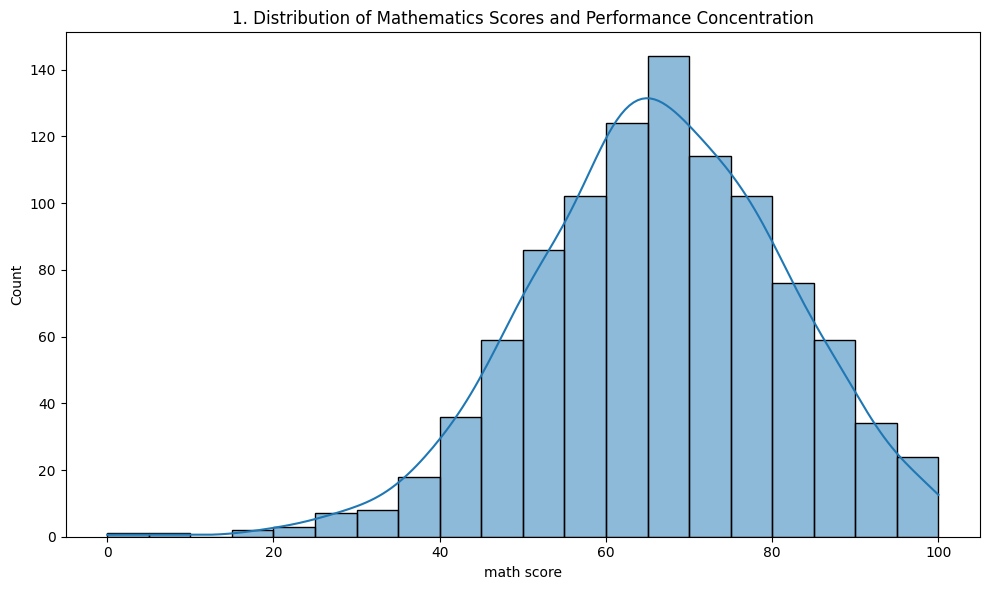

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='math score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Mathematics Scores and Performance Concentration')
show_fig()
plot_no += 1

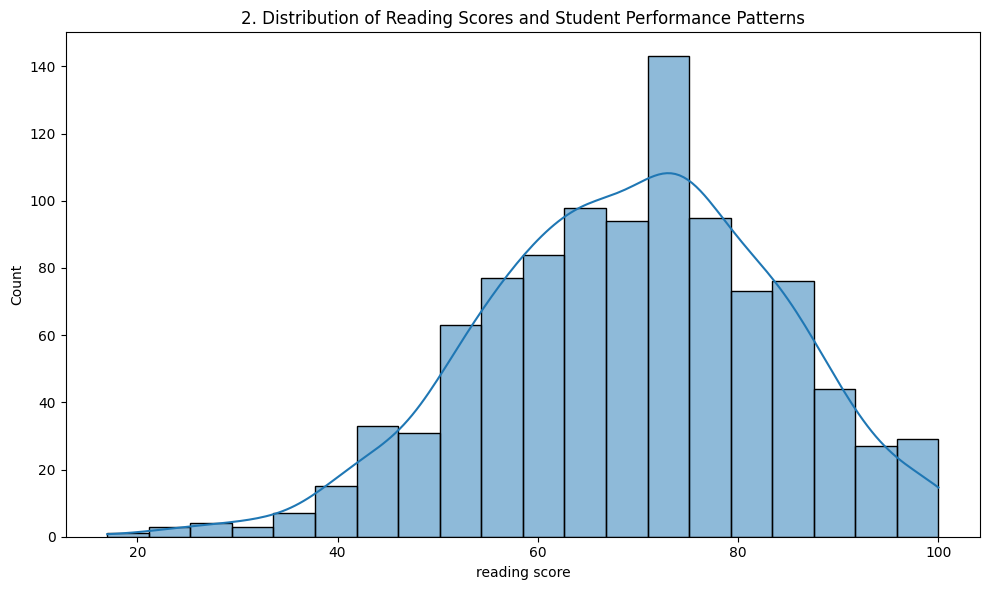

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='reading score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Reading Scores and Student Performance Patterns')
show_fig()
plot_no += 1

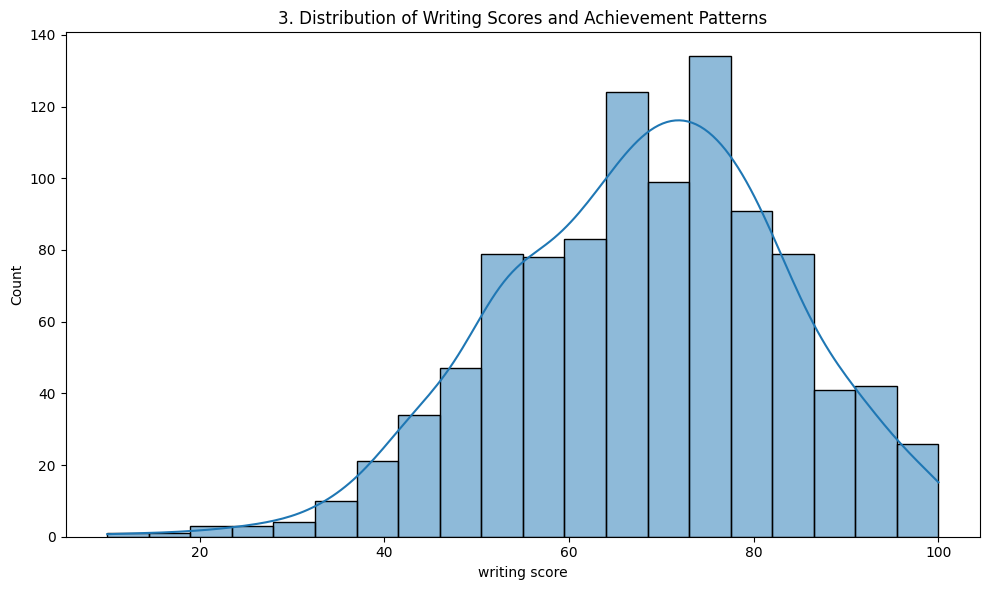

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='writing score', kde=True, bins=20)
plt.title(f'{plot_no}. Distribution of Writing Scores and Achievement Patterns')
show_fig()
plot_no += 1

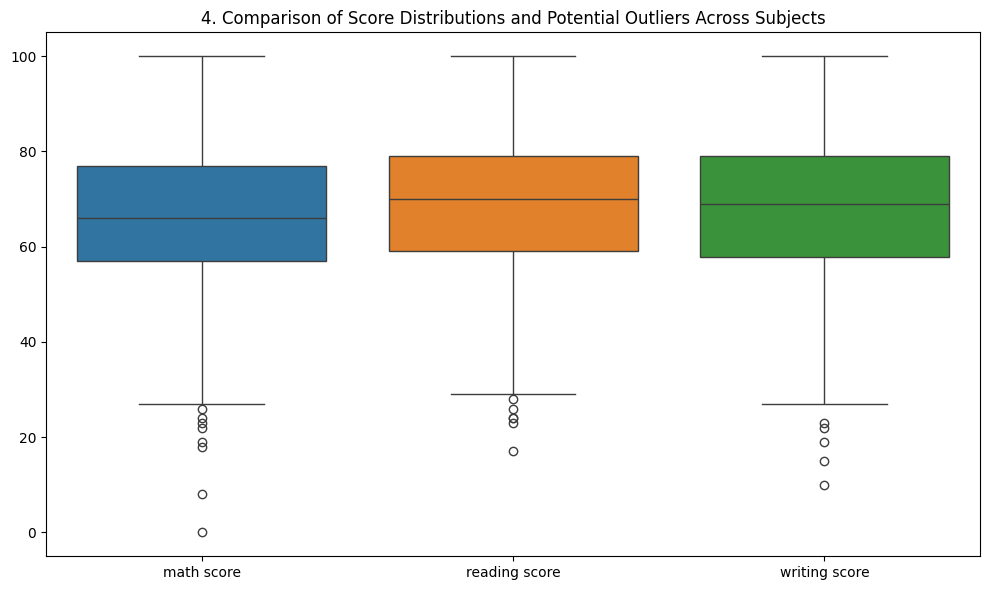

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df[['math score', 'reading score', 'writing score']])
plt.title(f'{plot_no}. Comparison of Score Distributions and Potential Outliers Across Subjects')
show_fig()
plot_no += 1

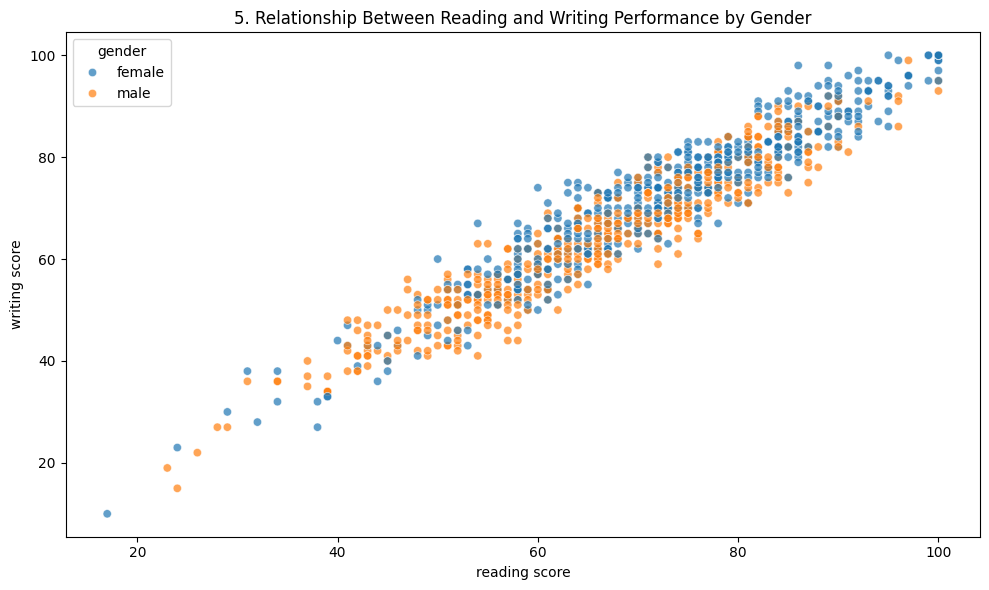

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='reading score', y='writing score', hue='gender', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Reading and Writing Performance by Gender')
show_fig()
plot_no += 1

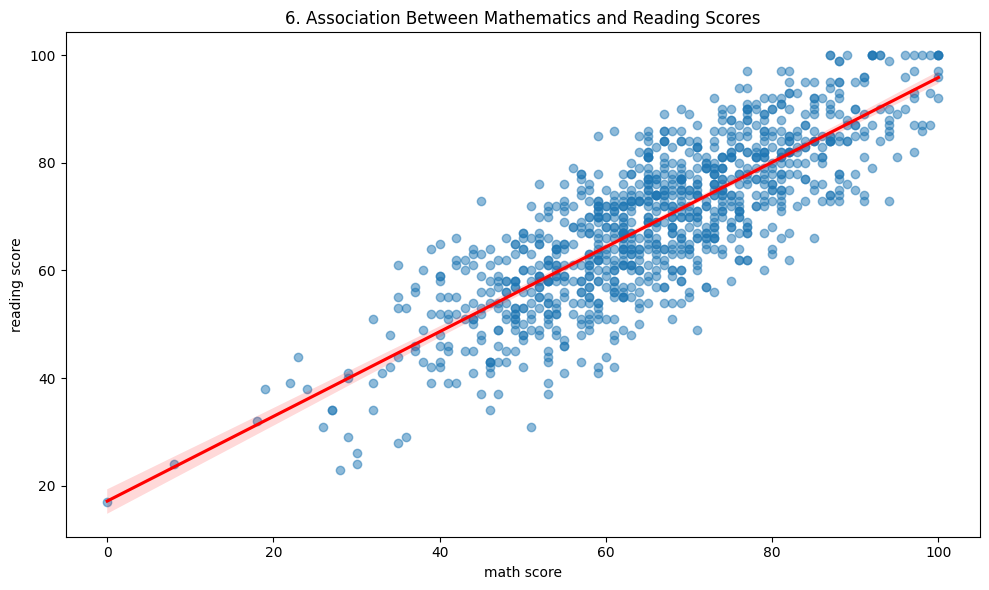

In [18]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='math score', y='reading score', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Mathematics and Reading Scores')
show_fig()
plot_no += 1

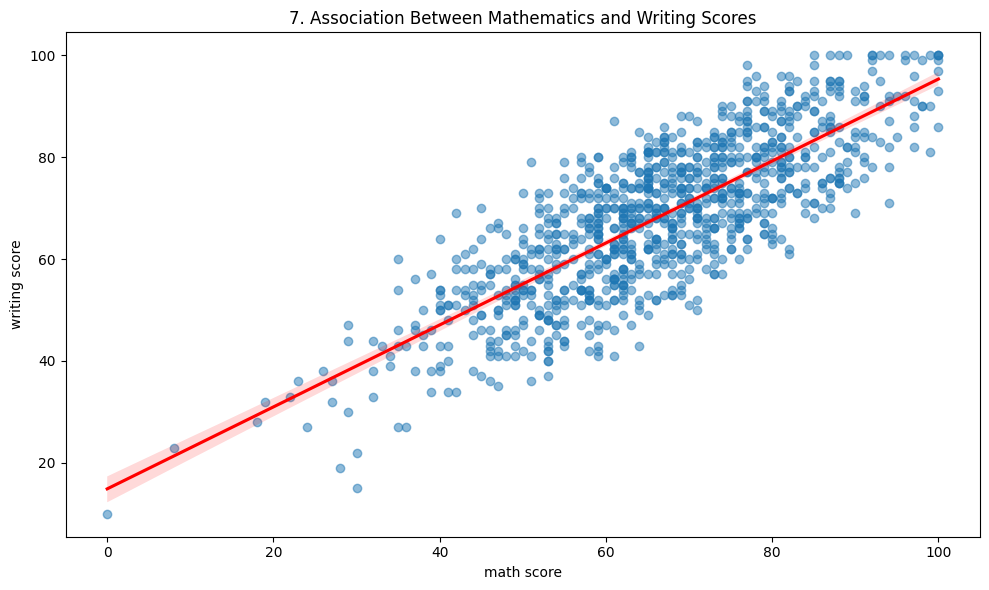

In [19]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='math score', y='writing score', scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Association Between Mathematics and Writing Scores')
show_fig()
plot_no += 1

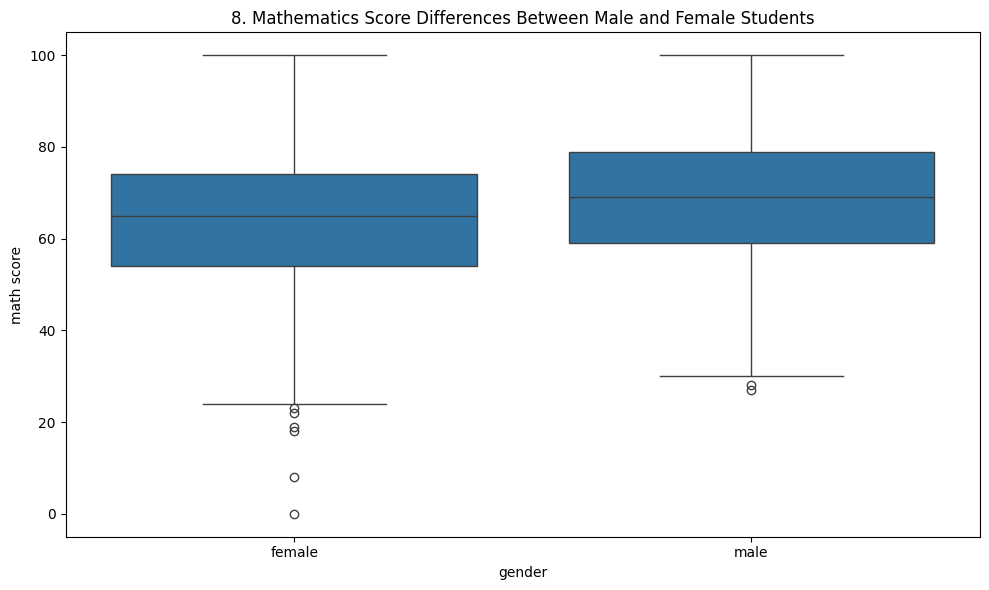

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='gender', y='math score')
plt.title(f'{plot_no}. Mathematics Score Differences Between Male and Female Students')
show_fig()
plot_no += 1

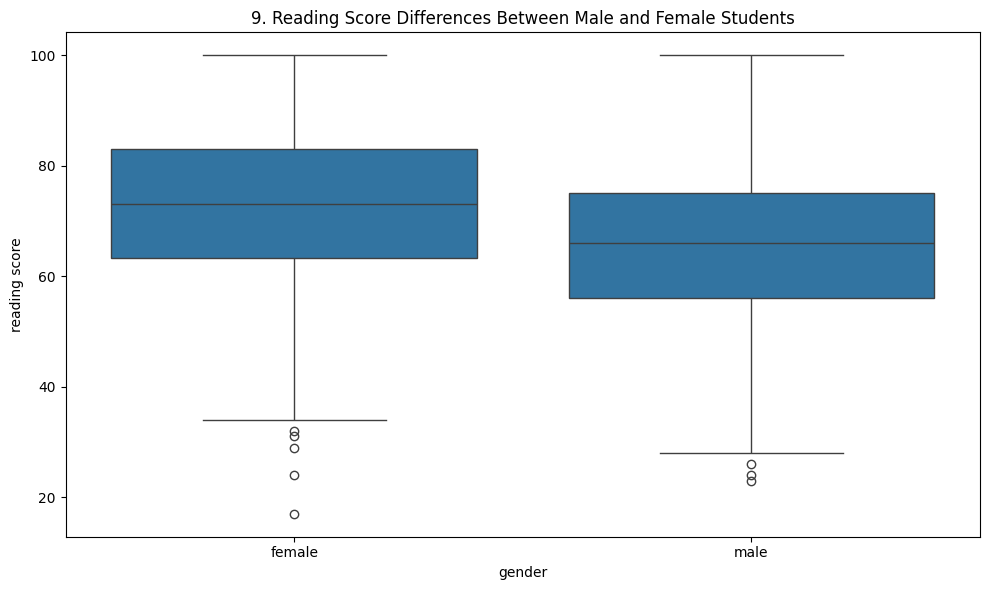

In [21]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='gender', y='reading score')
plt.title(f'{plot_no}. Reading Score Differences Between Male and Female Students')
show_fig()
plot_no += 1

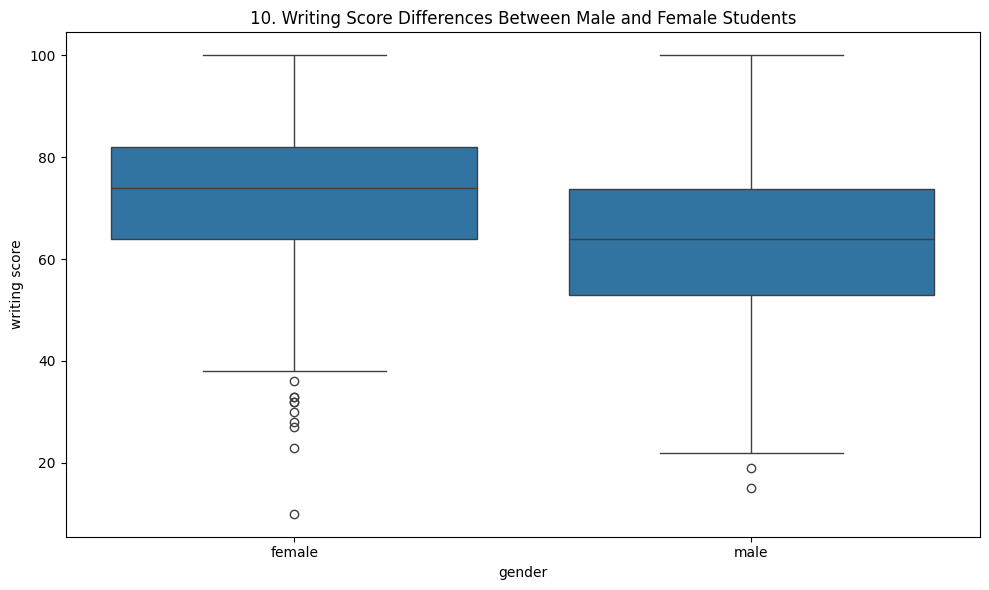

In [22]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='gender', y='writing score')
plt.title(f'{plot_no}. Writing Score Differences Between Male and Female Students')
show_fig()
plot_no += 1

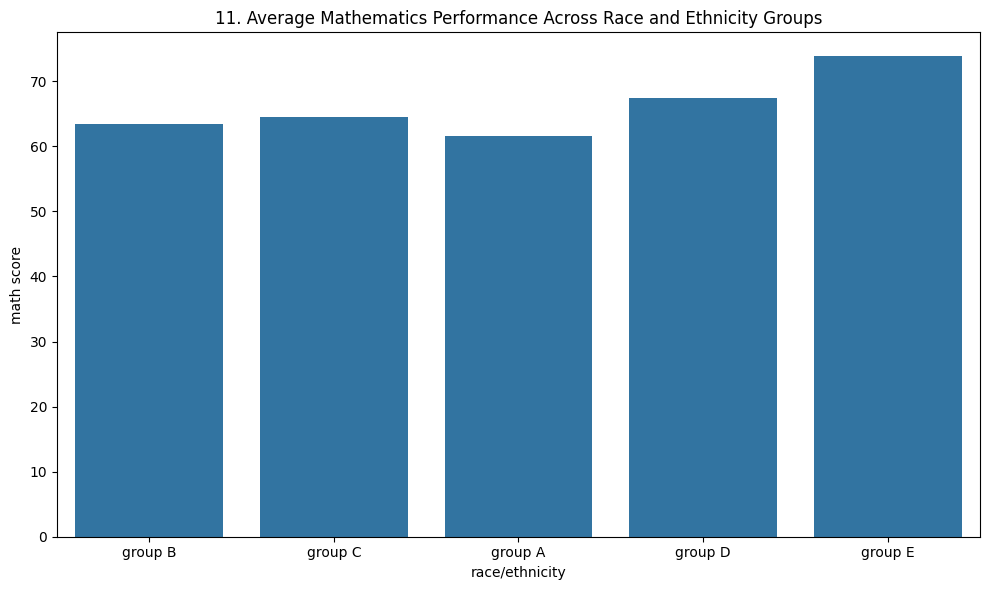

In [23]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='race/ethnicity', y='math score', errorbar=None)
plt.title(f'{plot_no}. Average Mathematics Performance Across Race and Ethnicity Groups')
show_fig()
plot_no += 1

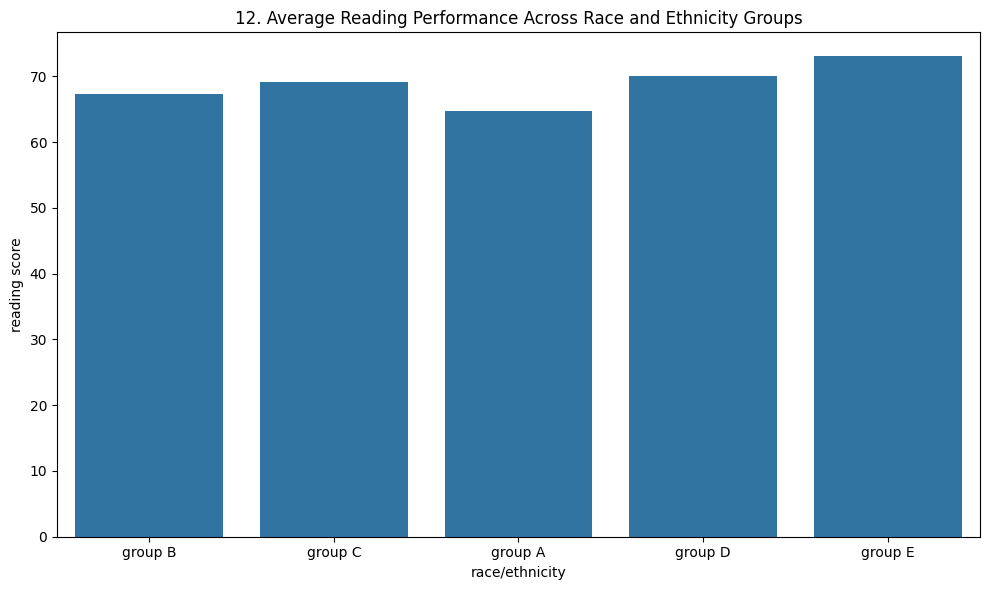

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='race/ethnicity', y='reading score', errorbar=None)
plt.title(f'{plot_no}. Average Reading Performance Across Race and Ethnicity Groups')
show_fig()
plot_no += 1

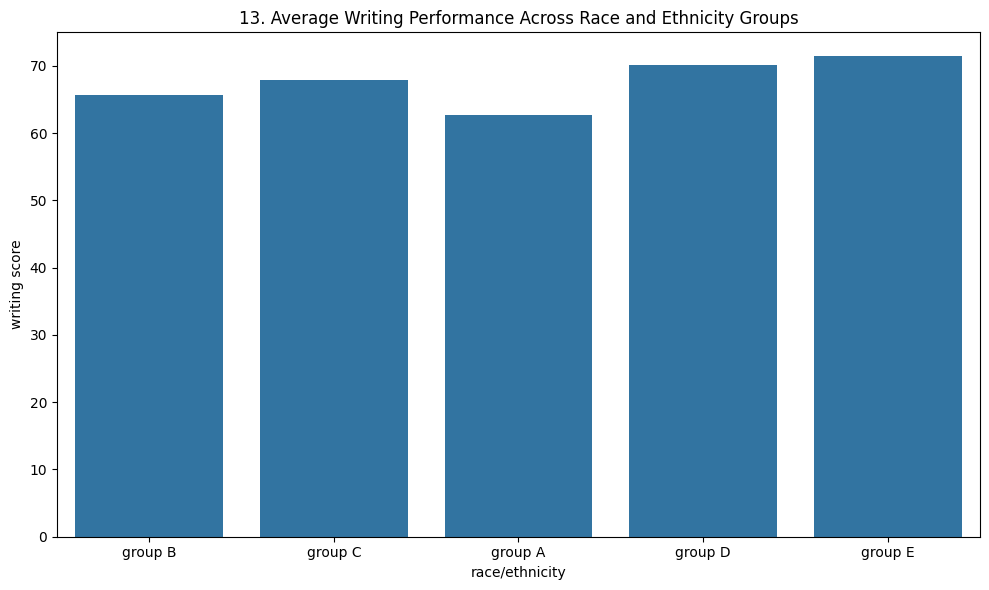

In [25]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='race/ethnicity', y='writing score', errorbar=None)
plt.title(f'{plot_no}. Average Writing Performance Across Race and Ethnicity Groups')
show_fig()
plot_no += 1

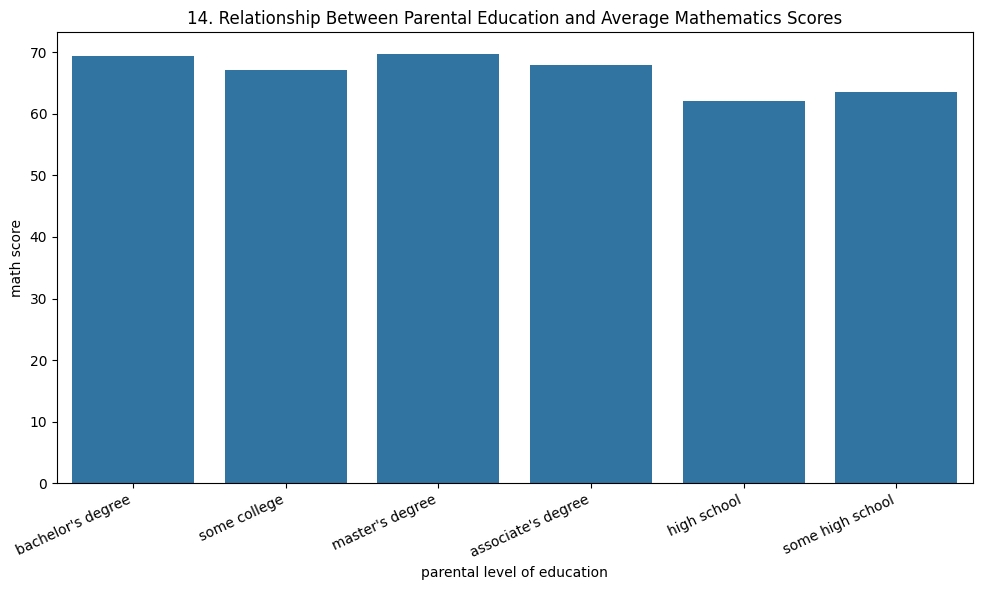

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='parental level of education', y='math score', errorbar=None)
plt.title(f'{plot_no}. Relationship Between Parental Education and Average Mathematics Scores')
plt.xticks(rotation=25, ha='right')
show_fig()
plot_no += 1

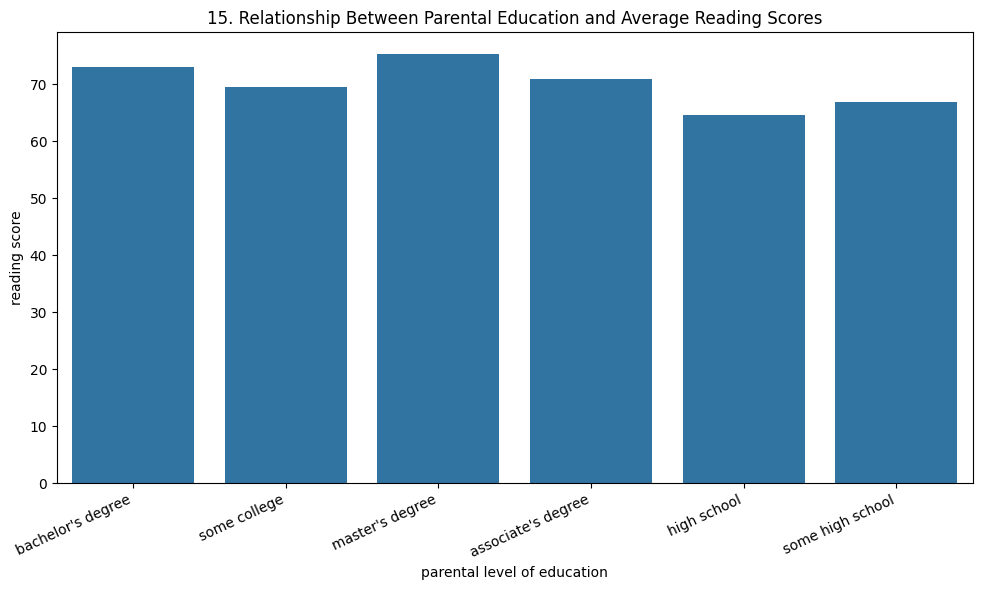

In [27]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='parental level of education', y='reading score', errorbar=None)
plt.title(f'{plot_no}. Relationship Between Parental Education and Average Reading Scores')
plt.xticks(rotation=25, ha='right')
show_fig()
plot_no += 1

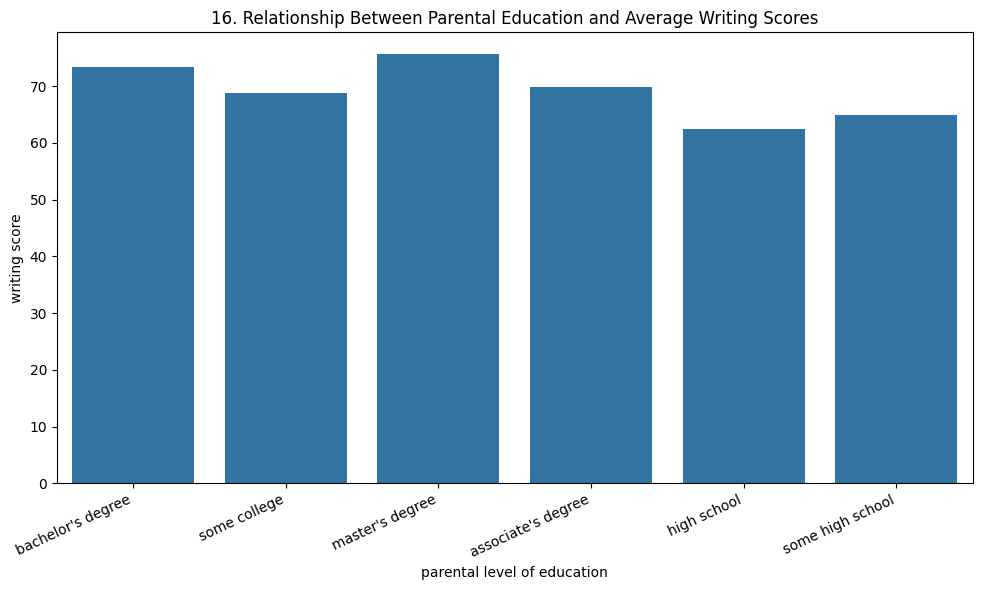

In [28]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='parental level of education', y='writing score', errorbar=None)
plt.title(f'{plot_no}. Relationship Between Parental Education and Average Writing Scores')
plt.xticks(rotation=25, ha='right')
show_fig()
plot_no += 1

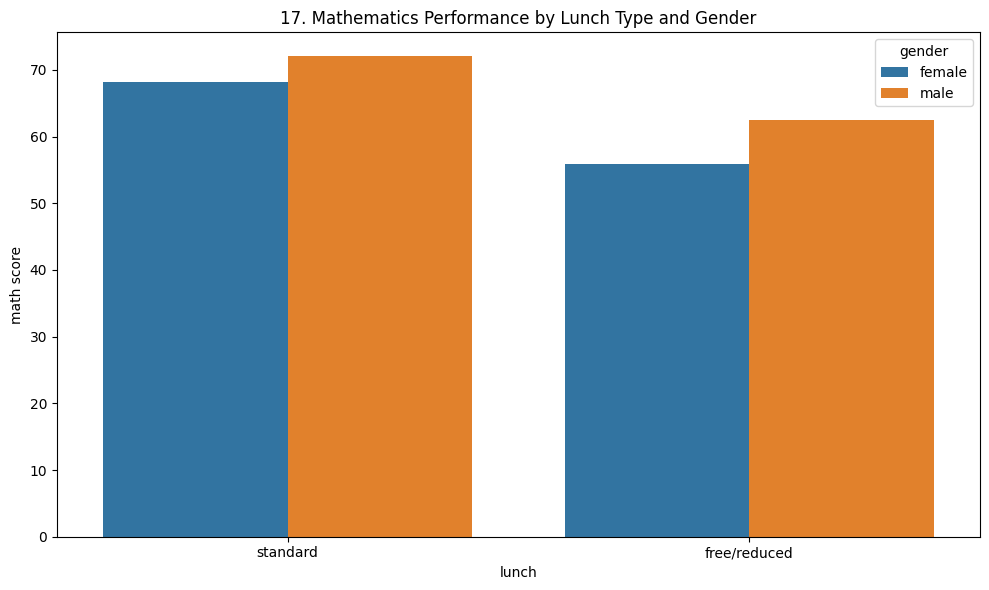

In [29]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='lunch', y='math score', hue='gender', errorbar=None)
plt.title(f'{plot_no}. Mathematics Performance by Lunch Type and Gender')
show_fig()
plot_no += 1

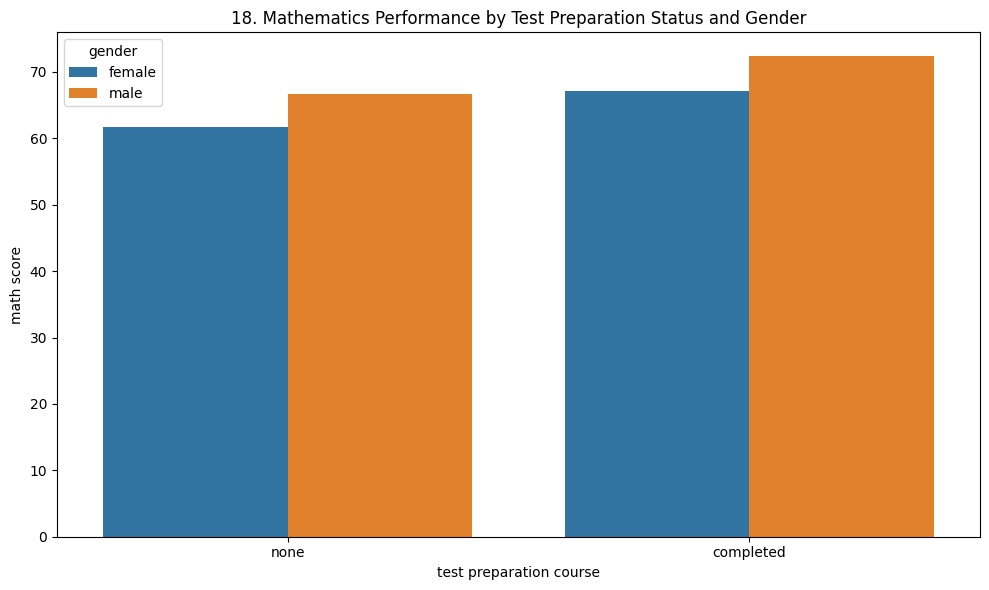

In [30]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='test preparation course', y='math score', hue='gender', errorbar=None)
plt.title(f'{plot_no}. Mathematics Performance by Test Preparation Status and Gender')
show_fig()
plot_no += 1

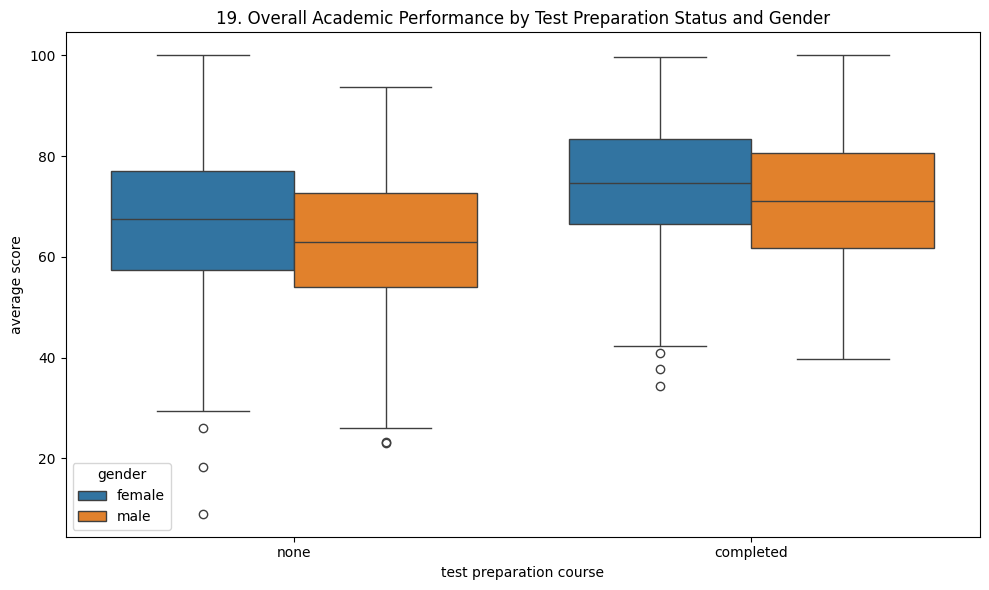

In [31]:
fig = plt.figure(figsize=(10,6))
df['average score'] = df[['math score', 'reading score', 'writing score']].mean(axis=1)
sns.boxplot(data=df, x='test preparation course', y='average score', hue='gender')
plt.title(f'{plot_no}. Overall Academic Performance by Test Preparation Status and Gender')
show_fig()
plot_no += 1

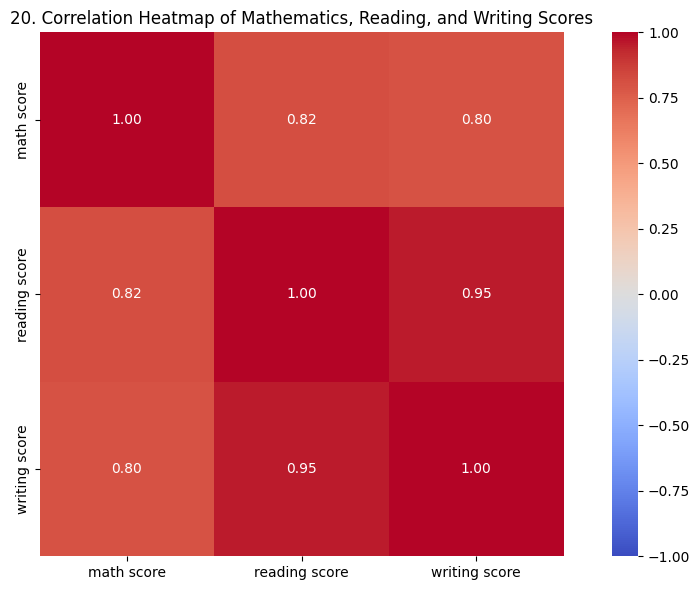

In [32]:
fig = plt.figure(figsize=(10,6))
corr = df[['math score', 'reading score', 'writing score']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, square=True)
plt.title(f'{plot_no}. Correlation Heatmap of Mathematics, Reading, and Writing Scores')
show_fig()
plot_no += 1

# Model Training

## Select features and target

In [33]:
X = df[['math score', 'reading score']]
y = df['writing score']

## Split data into training and testing sets

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Create and train the regression model

In [35]:
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
model.fit(X_train, y_train)

,steps,"[('standardscaler', ...), ('ridge', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None


## Predict writing scores

In [36]:
y_pred = model.predict(X_test)

## Evaluate model performance

In [37]:
print("R² Score:", round(r2_score(y_test, y_pred), 4))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Root Mean Squared Error:", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))

R² Score: 0.9018
Mean Absolute Error: 3.84
Root Mean Squared Error: 4.86


## Plot actual versus predicted scores

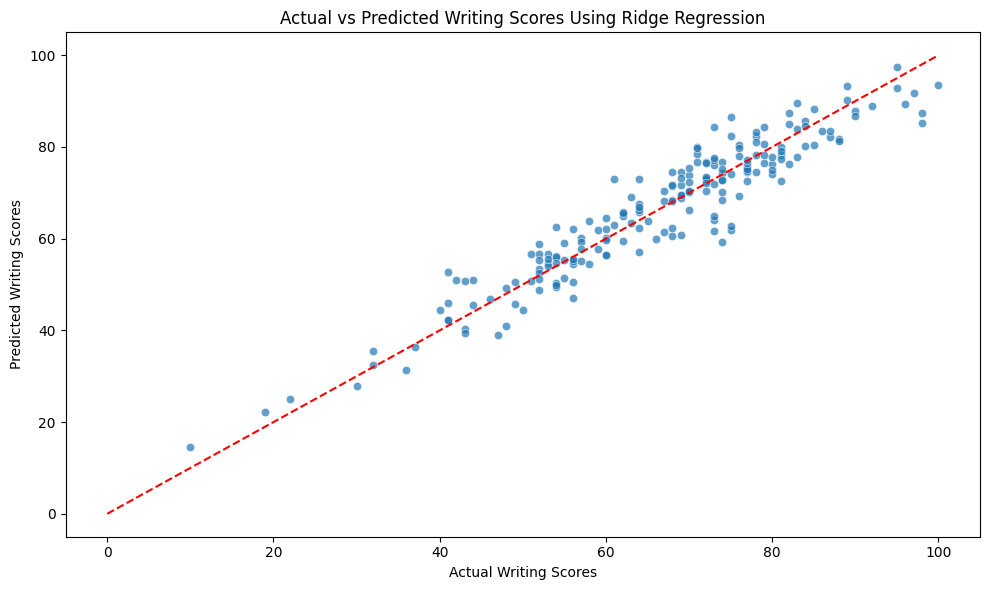

In [38]:
fig = plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.xlabel('Actual Writing Scores')
plt.ylabel('Predicted Writing Scores')
plt.title('Actual vs Predicted Writing Scores Using Ridge Regression')
show_fig()